# 04. Feature Extraction

**Objetivo:** Construir las variables predictoras del Random Forest. La extracción transforma los retornos y el estimador de Parkinson en una tabla con una fila por día objetivo $\tau$: las columnas de $X$ usan solo información hasta $\tau-1$ y la etiqueta $y$ es el Parkinson del día $\tau$. Se usa extracción clásica por rezagos, adecuada para una serie temporal estructurada; no se aplica transfer learning, que la rúbrica reserva para datos no estructurados. [3], [4]

## 0. Configuración

In [1]:
import sys
from pathlib import Path

In [2]:

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

In [3]:
RAIZ

WindowsPath('c:/Users/ASUS/Desktop/Maestria IA USFQ/AprendizajeSupervisado/Proyectofinal_ml_wti')

In [4]:
import numpy as np
import pandas as pd
import importlib
import matplotlib.pyplot as plt
from src import feature_extraction as fe
from src import config as cfg

In [5]:
importlib.reload(fe)

<module 'src.feature_extraction' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\AprendizajeSupervisado\\Proyectofinal_ml_wti\\src\\feature_extraction.py'>

In [6]:
PROC = RAIZ / "data" / "processed"
FIG_DIR = RAIZ / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [7]:
base_train_val = pd.read_csv(PROC / "train_validation.csv", index_col=0, parse_dates=True)   # WTI (%), WTI_park (%²)
base_test=pd.read_csv(PROC / "test.csv", index_col=0, parse_dates=True)
FOLDS = pd.read_csv(PROC / "folds.csv", parse_dates=["train_ini", "train_fin", "val_ini", "val_fin"])

print(base_train_val.shape, base_train_val.index.min().date(), "→", base_train_val.index.max().date())
print(base_test.shape, base_test.index.min().date(), "→", base_test.index.max().date())

(3769, 2) 2010-01-05 → 2024-12-31
(461, 2) 2025-01-02 → 2026-10-30


## 1. Feature Extraction (Construcción de variables predictoras por rezagos)

Para construir las variables predictoras se utilizan hasta 20 rezagos diarios (aproximadamente cuatro semanas bursátiles), con el fin de capturar tanto los efectos recientes como la persistencia de la volatilidad. 

Las variables se calculan sobre la serie completa (desarrollo y test) y después se separan en desarrollo (hasta el 31-dic-2024) y test (desde el 2-ene-2025). Esto no introduce fuga de información: cada rezago y promedio móvil es una fórmula fija que solo usa días anteriores a τ. Así, los primeros días del test tienen sus rezagos calculados con los últimos días de 2024, igual que ocurriría al pronosticar en tiempo real. Ningún parámetro se estima en este paso. La selección de variables y el entrenamiento del modelo se realizan después, dentro de cada fold y solo con sus observaciones de entrenamiento. [3], [4]

| Columnas | Qué representan | Unidades |
|---|---|---|
| `r2_lag1` … `r2_lag20` | Retornos de 1,....,20 días anteriores elevados al cuadrado. Miden la magnitud de los movimientos, independientemente de su signo. | $\%^2$ |
| `absr_lag1` … `absr_lag20` | Valor absoluto de los retornos de 1,..., 20 días anteriores. Miden la magnitud del movimiento sin elevarlo al cuadrado. | % |
| `park_lag1` … `park_lag20` | Estimadores de Parkinson (WTI_PARK construidos en el notebook 01) de 1,..., 20 días anteriores. | $\%^2$ |
| `vol_r_5`, `vol_r_21`, `vol_r_63` | Desviación estándar móvil de los retornos de los últimos 5, 21 o 63 días, calculada hasta $\tau-1$. Resume la volatilidad reciente. Por ejemplo para `vol_r_5` en la fecha objetivo $\tau$, se calcula la desviación estándar de los retornos de las cinco sesiones anteriores, desde $r_{\tau-5}$ hasta $r_{\tau-1}$: $\text{vol\_r\_5}_\tau=\sqrt{\frac{1}{5-1}\sum_{i=\tau-5}^{\tau-1}(r_i-\bar r)^2}$ donde $\bar r$ es el promedio de esos cinco retornos. | % |
| `park_media_5`, `park_media_21`, `park_media_63` | Promedio móvil del estimador de Parkinson de los últimos 5, 21 o 63 días, calculado hasta $\tau-1$. Por ejemplo `park_media_5` en la fecha objetivo $\tau$ es el promedio de los estimadores de Parkinson de las cinco sesiones anteriores, desde $\tau-5$ hasta $\tau-1$:$\text{park\_media\_5}_\tau=\frac{1}{5}\sum_{i=\tau-5}^{\tau-1} \text{WTI\_park}_i$. No incluye el estimador de Parkinson del propio día objetivo $\tau$. | %² |
| `r_lag1` | Retorno del día anterior, conservando su signo. Puede ayudar a identificar si los retornos positivos y negativos se relacionan de manera distinta con la volatilidad. | % | [4]

Se usa `WTI_park` como variable objetivo porque la volatilidad verdadera del WTI no se observa directamente y se necesita una medida estimada para que el Random Forest aprenda a pronosticarla.

WTI_park es el estimador de varianza diaria de Parkinson, calculado con el precio máximo ($H_t$) y mínimo ($L_t$) de la sesión:

$$\text{WTI\_park}_t = \frac{[100\ln(H_t/L_t)]^2}{4\ln 2}$$

Con la escala 100 queda expresado en %². Mide cuánto varió el precio durante el día, no la dirección del cambio. Por ejemplo, si en una sesión el máximo es 101,18 y el mínimo 100, el estimador es ≈ 0,5 %² y su raíz ≈ 0,71 %: una estimación de la volatilidad diaria a partir del rango intradía, no el cambio entre apertura y cierre. [1]


Imaginemos que el precio del petróleo abre en 100. Durante el día sube hasta 101.18, baja hasta 100 y cierra en 100.50. Parkinson usa el máximo (101.18) y el mínimo (100) para estimar la variabilidad del día. Con ese rango, el estimador sería aproximadamente `0.5 %²`; al sacar su raíz, obtenemos `0.71 %`. Ese 0.71 % resume la volatilidad diaria estimada: no significa que el precio haya cambiado exactamente 0.71 % entre apertura y cierre ni entre el máximo y el mínimo. [1], [3]

Por tanto, $y_\tau$=WTI_park es el Parkinson del día que se desea pronosticar ya calculado en el notebook 01 y representado  en unidades de \(\%²\). 

Para la fila cuyo objetivo es el Parkinson del 15 de enero, las variables usan solo valores anteriores. Si n_lags=20, se incluyen los últimos 20 días de negociación:
- r2_lag1 = retorno del 14 de enero al cuadrado; r2_lag20 = retorno de hace 20 sesiones al cuadrado.
- absr_lag1 y absr_lag20 = valor absoluto de esos mismos retornos, sin elevarlos al cuadrado.
- park_lag1 y park_lag20 = estimador de Parkinson de esas fechas anteriores; no se vuelve a elevar al cuadrado, pues ya está expresado en %².
- vol_r_21 = desviación estándar de los retornos de las 21 sesiones anteriores, hasta el 14 de enero.
- park_media_21 = promedio de Parkinson de esas 21 sesiones anteriores.
- r_lag1 = retorno del 14 de enero conservando su signo.
- y = Parkinson del 15 de enero, que es lo que el modelo intenta pronosticar.

La función devuelve $X$ e $y$ por separado y elimina las primeras filas que no tienen suficiente historial para calcular todas las ventanas y rezagos. [1], [4] 

In [8]:
base=pd.concat([base_train_val,base_test])

In [9]:
base.head()

,WTI,WTI_park
Date,,
2010-01-05,0.318465,0.599044
2010-01-06,1.709655,3.807394
2010-01-07,-0.627108,0.636423
2010-01-08,0.108816,1.473154
2010-01-11,-0.278337,2.075756


In [10]:
# Verificar si hay fechas duplicadas
hay_duplicados = base.index.has_duplicates
print("¿Hay fechas duplicadas?", hay_duplicados)

# Mostrar las fechas duplicadas, si existen
if hay_duplicados:
    print(base.index[base.index.duplicated(keep=False)].sort_values())

¿Hay fechas duplicadas? False


In [11]:
base.shape

(4230, 2)

In [12]:
X, y = fe.construir_features(base,n_lags=20)

print(f"Variables candidatas: {X.shape[1]}")
print(f"Observaciones: {len(X)} | {X.index.min().date()} → {X.index.max().date()}")
print(f"Días descartados al inicio por falta de historia: {len(base) - len(X)}")
X.head()

Variables candidatas: 67
Observaciones: 4167 | 2010-04-07 → 2026-10-30
Días descartados al inicio por falta de historia: 63


,r2_lag1,absr_lag1,park_lag1,r2_lag2,absr_lag2,park_lag2,r2_lag3,absr_lag3,park_lag3,r2_lag4,...,r2_lag20,absr_lag20,park_lag20,vol_r_5,park_media_5,vol_r_21,park_media_21,vol_r_63,park_media_63,r_lag1
Date,,,,,,,,,,,,,,,,,,,,,
2010-04-07,0.064340,0.253654,0.443128,4.165706,2.041006,1.651925,1.733202,1.316511,2.054802,2.800357,...,0.216445,0.465237,1.682206,0.823347,1.208274,1.333262,1.982266,1.674965,3.015653,0.253654
2010-04-08,1.235735,1.111636,1.061799,0.064340,0.253654,0.443128,4.165706,2.041006,1.651925,1.733202,...,0.538151,0.733587,2.649075,1.276383,1.320317,1.367688,1.961710,1.681642,3.022999,-1.111636
2010-04-09,0.327407,0.572195,1.119836,1.235735,1.111636,1.061799,0.064340,0.253654,0.443128,4.165706,...,0.000594,0.024366,0.593487,1.302254,1.266298,1.370594,1.934931,1.670465,2.980339,-0.572195
2010-04-12,0.304635,0.551938,2.512998,0.327407,0.572195,1.119836,1.235735,1.111636,1.061799,0.064340,...,1.134674,1.065211,3.610699,1.234618,1.357937,1.375331,1.928451,1.670006,3.010126,-0.551938
2010-04-13,0.469692,0.685341,1.329691,0.304635,0.551938,2.512998,0.327407,0.572195,1.119836,1.235735,...,3.198435,1.788417,2.663887,0.494658,1.293490,1.387532,1.963508,1.672495,3.007849,-0.685341


## 2. Validaciones y comprobaciones del feature extraction

Se comprueba la construcción de las columnas mediante rezagos de una fecha determinada: `07 de Abril del 2010`. 

In [13]:
base_hasta_abril7 = base.loc[: "2010-04-07"]
base_hasta_abril7

,WTI,WTI_park
Date,,
2010-01-05,0.318465,0.599044
2010-01-06,1.709655,3.807394
2010-01-07,-0.627108,0.636423
2010-01-08,0.108816,1.473154
2010-01-11,-0.278337,2.075756
...,...,...
2010-03-31,1.673427,1.389933
2010-04-01,1.316511,2.054802
2010-04-05,2.041006,1.651925


In [14]:
X[:1]

,r2_lag1,absr_lag1,park_lag1,r2_lag2,absr_lag2,park_lag2,r2_lag3,absr_lag3,park_lag3,r2_lag4,...,r2_lag20,absr_lag20,park_lag20,vol_r_5,park_media_5,vol_r_21,park_media_21,vol_r_63,park_media_63,r_lag1
Date,,,,,,,,,,,,,,,,,,,,,
2010-04-07,0.06434,0.253654,0.443128,4.165706,2.041006,1.651925,1.733202,1.316511,2.054802,2.800357,...,0.216445,0.465237,1.682206,0.823347,1.208274,1.333262,1.982266,1.674965,3.015653,0.253654


En la fila del 7 de abril de 2010, r2_lag1 = 0,0643 es el cuadrado del retorno del 6 de abril (0,2537), absr_lag1 y r_lag1 son ese mismo retorno, y park_lag1 = 0,4431 y park_lag2 = 1,6519 son los estimadores de Parkinson del 6 y del 5 de abril. Los rezagos están correctamente alineados.

A continuación, se comprueba que  las características de una fecha usan solo información disponible hasta el día anterior, y que la variable objetivo corresponde al mismo día. Es una verificación para detectar errores de alineación o uso accidental de información futura [4], [5]

In [15]:
pos = 100
t = X.index[pos]
dia_anterior = base.index[base.index.get_loc(t) - 1]
r_hasta_ayer = base["WTI"].loc[:dia_anterior]

assert np.isclose(X.loc[t, "park_lag1"], base.loc[dia_anterior, "WTI_park"])
assert np.isclose(X.loc[t, "r2_lag1"], base.loc[dia_anterior, "WTI"]**2)
assert np.isclose(X.loc[t, "vol_r_5"], r_hasta_ayer.iloc[-5:].std())
assert np.isclose(X.loc[t, "park_media_21"], base["WTI_park"].loc[:dia_anterior].iloc[-21:].mean())
assert np.isclose(y.loc[t], base.loc[t, "WTI_park"])
print(f"Día τ = {t.date()}: las variables usan información hasta {dia_anterior.date()} ✔")

Día τ = 2010-08-27: las variables usan información hasta 2010-08-26 ✔


In [16]:
grupos = {
    "r2_lag":     ("Rezago del retorno al cuadrado", "%²"),
    "absr_lag":   ("Rezago del retorno en valor absoluto", "%"),
    "park_lag":   ("Rezago del estimador de Parkinson", "%²"),
    "vol_r_":     ("Desviación estándar móvil del retorno", "%"),
    "park_media_": ("Promedio móvil del estimador de Parkinson", "%²"),
    "r_lag1":     ("Retorno del día anterior (con signo)", "%"),
}

def describir(col):
    for pref, (desc, unidad) in grupos.items():
        if col.startswith(pref):
            detalle = col.replace(pref, "")
            if "lag" in pref and pref != "r_lag1":
                detalle = f"τ-{detalle}"
            elif pref != "r_lag1":
                detalle = f"ventana de {detalle} días"
            else:
                detalle = "τ-1"
            return pd.Series({"descripción": desc, "detalle": detalle, "unidad": unidad})

diccionario = X.columns.to_series().apply(describir)
display(diccionario)
display(diccionario["descripción"].value_counts().to_frame("n variables"))

,descripción,detalle,unidad
r2_lag1,Rezago del retorno al cuadrado,τ-1,%²
absr_lag1,Rezago del retorno en valor absoluto,τ-1,%
park_lag1,Rezago del estimador de Parkinson,τ-1,%²
r2_lag2,Rezago del retorno al cuadrado,τ-2,%²
absr_lag2,Rezago del retorno en valor absoluto,τ-2,%
...,...,...,...
vol_r_21,Desviación estándar móvil del retorno,ventana de 21 días,%
park_media_21,Promedio móvil del estimador de Parkinson,ventana de 21 días,%²
vol_r_63,Desviación estándar móvil del retorno,ventana de 63 días,%
park_media_63,Promedio móvil del estimador de Parkinson,ventana de 63 días,%²


,n variables
descripción,
Rezago del retorno al cuadrado,20
Rezago del retorno en valor absoluto,20
Rezago del estimador de Parkinson,20
Desviación estándar móvil del retorno,3
Promedio móvil del estimador de Parkinson,3
Retorno del día anterior (con signo),1


En las tablas se muestra que se construyeron 67 variables predictoras para el Random Forest. Incluye:

- 60 rezagos: 20 retornos al cuadrado (%²), 20 retornos absolutos (%) y 20 estimadores de Parkinson (%²), correspondientes a las 20 sesiones anteriores.
- 6 medidas móviles: desviación estándar de los retornos y promedio de Parkinson para ventanas de 5, 21 y 63 sesiones.
- 1 retorno con signo: el retorno de la sesión anterior (%).

En total, las variables combinan movimientos recientes con medidas de volatilidad de corto, mediano y largo plazo. Todas se calculan con información previa al día objetivo. [3], [4]

### 2.1 Train y Test

In [22]:
corte = pd.Timestamp(cfg.DEV_FIN)

X.index = pd.to_datetime(X.index)
X_train = X.loc[X.index <= corte].copy()
X_test = X.loc[X.index > corte].copy()

print("X_train:", X_train.shape, X_train.index.min(), "→", X_train.index.max())
print("X_test: ", X_test.shape, X_test.index.min(), "→", X_test.index.max())

X_train: (3706, 67) 2010-04-07 00:00:00 → 2024-12-31 00:00:00
X_test:  (461, 67) 2025-01-02 00:00:00 → 2026-10-30 00:00:00


In [18]:
y.index = pd.to_datetime(y.index)
y_train = y.loc[y.index <= corte].copy()
y_test = y.loc[y.index > corte].copy()

print("y_train:", y_train.shape, y_train.index.min(), "→", y_train.index.max())
print("y_test: ", y_test.shape, y_test.index.min(), "→", y_test.index.max())

y_train: (3706,) 2010-04-07 00:00:00 → 2024-12-31 00:00:00
y_test:  (461,) 2025-01-02 00:00:00 → 2026-10-30 00:00:00


## 3. Análisis de Correlación

In [19]:
f_diag = FOLDS.loc[FOLDS["train_fin"].idxmin()]          # Rep 2 · Fold 1, train hasta 2019-06-30
tr = (X_train.index >= f_diag.train_ini) & (X_train.index <= f_diag.train_fin)

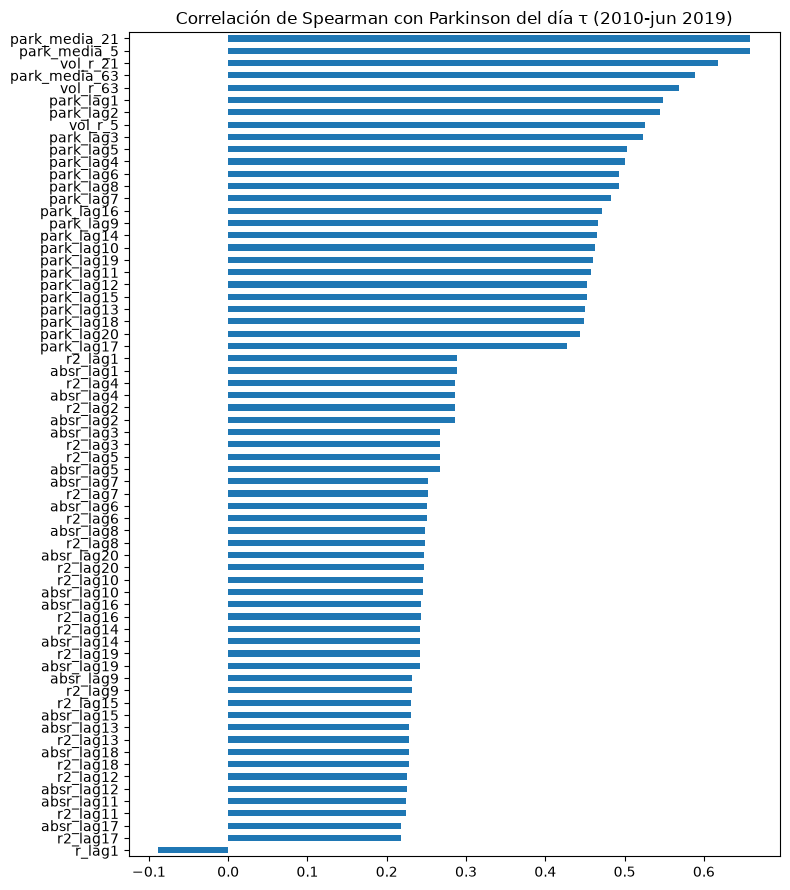

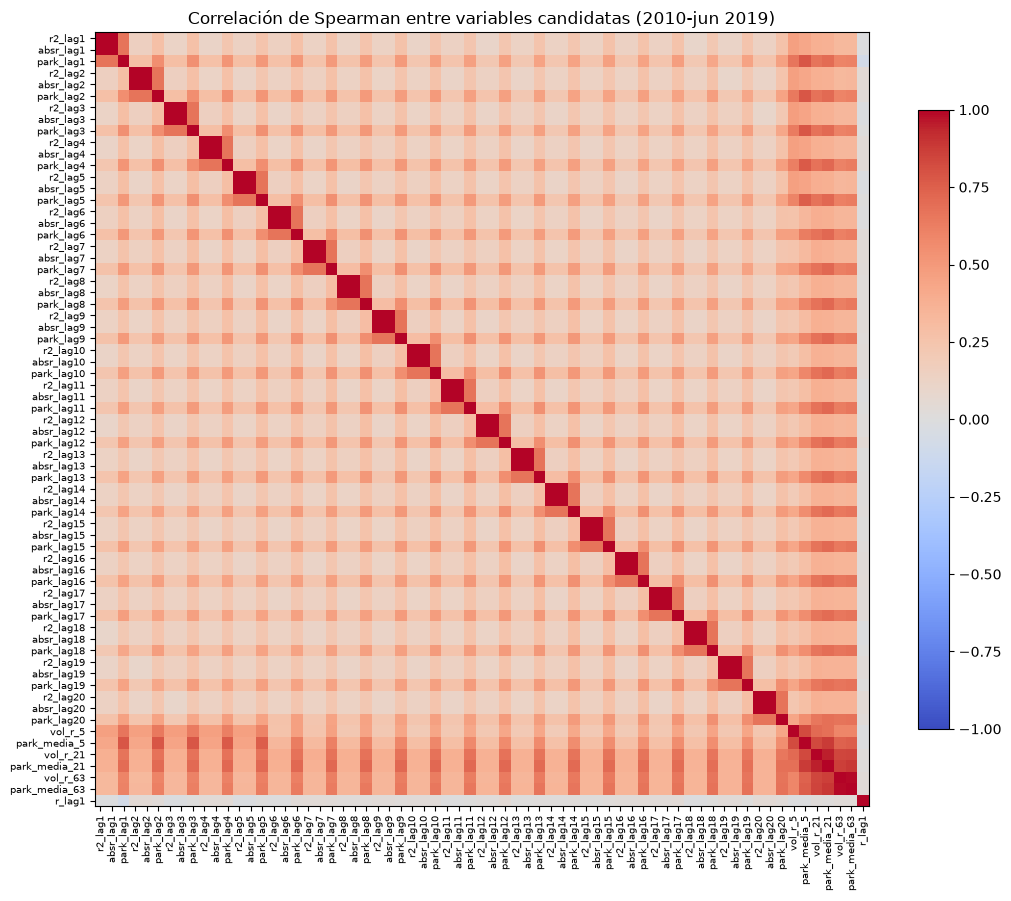

In [20]:
# Correlación de Spearman con la etiqueta (relación monótona, robusta a valores extremos)
corr_y = X_train[tr].corrwith(y_train[tr], method="spearman").sort_values()
corr_y.plot.barh(figsize=(8, 9), title="Correlación de Spearman con Parkinson del día τ (2010-jun 2019)")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_correlacion_features_y.png", dpi=150); plt.show()

# Redundancia entre variables
corr_X = X_train[tr].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_X, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_X)), corr_X.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr_X)), corr_X.columns, fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación de Spearman entre variables candidatas (2010-jun 2019)")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_correlacion_entre_features.png", dpi=150); plt.show()

Se muestra la correlación de Spearman entre cada variable candidata y el Parkinson del día objetivo. Las asociaciones más altas son positivas y corresponden a promedios móviles de Parkinson y volatilidad: park_media_21 y park_media_5, vol_r_21  y otros indicadores de volatilidad. Esto sugiere que los periodos con volatilidad reciente alta tienden a coincidir con un Parkinson alto el día siguiente. Los retornos al cuadrado y absolutos tienen correlaciones positivas más moderadas; r_lag1 presenta una asociación negativa débil. Son asociaciones monotónicas, no evidencia de causalidad ni garantía de buen pronóstico.

El mapa de calor muestra que varias características también están correlacionadas entre sí, especialmente los rezagos de Parkinson y las ventanas móviles de volatilidad. Hay redundancia entre algunas variables. El Random Forest puede manejar predictores correlacionados, pero esa redundancia puede repartir la importancia entre ellos; por eso conviene evaluar la selección de características con validación temporal y solo dentro de los datos de entrenamiento de cada fold. [2], [3], [6]

## 4. Guardar

In [21]:
X_train.to_csv(PROC / "fe_features_X.csv")
y_train.to_csv(PROC / "fe_features_y.csv")
X_test.to_csv(PROC / "fe_features_X_test.csv")
y_test.to_csv(PROC / "fe_features_y_test.csv")
diccionario.to_csv(PROC / "features_diccionario.csv")
print("Guardado en", PROC)

Guardado en c:\Users\ASUS\Desktop\Maestria IA USFQ\AprendizajeSupervisado\Proyectofinal_ml_wti\data\processed


## 5. Conclusiones


- Se construyeron 67 variables candidatas por rezagos: 20 de $r^2$, 20 de $|r|$, 20 de Parkinson, la volatilidad móvil y el Parkinson promedio en ventanas de 5, 21 y 63 días, y el retorno del día anterior con signo.
- Todas usan solo información hasta $\tau-1$, lo que se verificó en fechas específicas. Se descartan los primeros 63 días por falta de historial: el desarrollo queda con 3.706 observaciones (7-abr-2010 a 31-dic-2024) y el test con 461 (2-ene-2025 a 30-oct-2026).
- Las variables más asociadas con el Parkinson del día siguiente son los promedios móviles de Parkinson y la volatilidad móvil (Spearman ≈ 0,6). Hay alta redundancia entre ellas, lo que justifica aplicar selección de variables en el notebook 05.

## 6. Referencias



[1] M. Parkinson, "The extreme value method for estimating the variance of the rate of return," *J. Business*, vol. 53, no. 1, pp. 61–65, 1980, doi: 10.1086/296071.

[2] C. Spearman, "The proof and measurement of association between two things," *Amer. J. Psychol.*, vol. 15, no. 1, pp. 72–101, 1904, doi: 10.2307/1412159.

[3] L. Breiman, "Random forests," *Mach. Learn.*, vol. 45, no. 1, pp. 5–32, 2001, doi: 10.1023/A:1010933404324.

[4] The pandas development team, "pandas documentation: DataFrame.shift, DataFrame.rolling y DataFrame.corr." [En línea]. Disponible en: https://pandas.pydata.org/docs/. [Accedido: 20-nov-2026].

[5] C. R. Harris *et al.*, "Array programming with NumPy," *Nature*, vol. 585, no. 7825, pp. 357–362, 2020, doi: 10.1038/s41586-020-2649-2.

[6] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Comput. Sci. Eng.*, vol. 9, no. 3, pp. 90–95, 2007, doi: 10.1109/MCSE.2007.55.